# Task 2: Predictive Linear Regression Model Pipeline
**Dataset:** UCI Automobile (imports-85), 205 cars, goal is to predict the car **price** (a continuous number).

| Task requirement | Where it is done |
|---|---|
| Load a standard dataset with scikit-learn tools (`fetch_openml`) | Step 2 |
| Mean imputation | Step 5 (numeric columns) |
| Feature scaling | Step 5 (`StandardScaler`) |
| Categorical encoding | Step 5 (`OneHotEncoder`) |
| Regularized Ridge regression | Step 6 |
| Log R² and RMSE | Steps 6 to 8 (results table, saved as CSV) |


## Step 1: Import the libraries

In [1]:
import numpy as np                      # numpy: maths on numbers
import pandas as pd                     # pandas: tables of data
import matplotlib.pyplot as plt         # matplotlib: draws charts

from sklearn.model_selection import train_test_split, GridSearchCV, KFold   # split the data, tune settings, cross-validation
from sklearn.compose import ColumnTransformer         # applies different steps to number and text columns
from sklearn.pipeline import Pipeline                 # chains steps into one model
from sklearn.impute import SimpleImputer              # fills in missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder   # scales numbers, turns text into numbers
from sklearn.linear_model import LinearRegression, Ridge          # plain and regularized linear models
from sklearn.metrics import r2_score, mean_squared_error          # the two evaluation metrics

## Step 2: Load the dataset
The cell loads the Automobile dataset with scikit-learn (`fetch_openml`). If that download fails, it reads the same data from the UCI repository instead.

In [2]:
from sklearn.datasets import fetch_openml              # scikit-learn tool that downloads standard datasets
columns = ["symboling", "normalized-losses", "make", "fuel-type", "aspiration", "num-of-doors",      # the 26 column names of the dataset
           "body-style", "drive-wheels", "engine-location", "wheel-base", "length", "width",
           "height", "curb-weight", "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
           "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg",
           "highway-mpg", "price"]
number_names = ["symboling", "normalized-losses", "wheel-base", "length", "width", "height", "curb-weight",   # the columns that hold numbers
                "engine-size", "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
                "city-mpg", "highway-mpg", "price"]
try:
    autos = fetch_openml(name="autos", version=1, as_frame=True, parser="auto")     # load the Automobile dataset with scikit-learn
    data = autos.frame[columns].copy()                                              # keep the 26 columns in a fixed order
    for col in columns:                                                             # make the column types clear
        if col in number_names:
            data[col] = pd.to_numeric(data[col], errors="coerce")                   # number columns become floats
        else:
            data[col] = data[col].astype(object)                                    # text columns become plain text
    print("Loaded with scikit-learn fetch_openml")                                   # confirm it worked
except Exception as error:                                                          # if the download fails
    print("fetch_openml failed:", error)                                            # show why
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"   # backup: the same data from UCI
    data = pd.read_csv(url, header=None, names=columns, na_values="?")              # "?" in this file means "missing"
    print("Loaded from UCI instead")                                                # confirm the backup worked
print(data.shape)                                                                   # expected: (205, 26)
data.head()                                                                         # show the first 5 cars

Loaded with scikit-learn fetch_openml
(205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [3]:
print(data.isnull().sum()[data.isnull().sum() > 0])    # columns that have missing values and how many

normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


## Step 3: Target, features and train/test split
Cars without a known price cannot be used for training or testing, so they are removed.

In [4]:
data = data.dropna(subset=["price"])           # remove cars with no price (4 cars)
X = data.drop(columns=["price"])               # features: everything except the price
y = data["price"]                              # target: the price
print("Features:", X.shape, "Target:", y.shape)   # expected: (201, 25) and (201,)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          # 20% of the cars are kept for the final test
    random_state=42)         # same split every time the notebook runs
print("Train:", X_train.shape, "Test:", X_test.shape)   # expected: 160 and 41 cars

Features: (201, 25) Target: (201,)
Train: (160, 25) Test: (41, 25)


## Step 4: Separate number columns from text columns

In [5]:
num_cols = X.select_dtypes(include="number").columns.tolist()      # columns that hold numbers
cat_cols = X.select_dtypes(exclude="number").columns.tolist()      # columns that hold text categories
print("Numeric columns    :", len(num_cols), num_cols)             # expected: 15 columns
print("Categorical columns:", len(cat_cols), cat_cols)             # expected: 10 columns

Numeric columns    : 15 ['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg']
Categorical columns: 10 ['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']


## Step 5: Preprocessing (mean imputation, scaling, categorical encoding)
Every step is learned from the training data only and then applied to the test data, so no test information leaks into training.

In [6]:
numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),            # fill missing numbers with the column mean
    ("scale", StandardScaler())])                          # scale every number column to mean 0 and spread 1
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),   # fill missing categories with the most common value
    ("encode", OneHotEncoder(handle_unknown="ignore"))])   # turn each category into 0/1 columns
preprocess = ColumnTransformer([
    ("num", numeric_steps, num_cols),                      # apply the number steps to number columns
    ("cat", categorical_steps, cat_cols)])                 # apply the category steps to text columns

## Step 6: Train the Ridge regression model and log R² and RMSE
Ridge is linear regression with an L2 penalty (`alpha`) that keeps the coefficients small and stable.

In [7]:
results = []                                                              # a list that collects every result

def log_metrics(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)                                         # R²: share of the price variation explained (1.0 is perfect)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))                    # RMSE: typical error in dollars
    results.append({"Model": name, "R2": round(r2, 4), "RMSE ($)": round(rmse, 2)})   # store the result
    print(f"{name}:  R2 = {r2:.4f}   RMSE = ${rmse:,.2f}")                # print the result

In [8]:
ridge_model = Pipeline([
    ("preprocess", preprocess),                # all preprocessing steps from Step 5
    ("ridge", Ridge(alpha=1.0))])              # Ridge regression with alpha = 1.0
ridge_model.fit(X_train, y_train)              # learn from the 160 training cars
ridge_pred = ridge_model.predict(X_test)       # predict prices of the 41 test cars
log_metrics("Ridge (alpha=1.0)", y_test, ridge_pred)   # log R² and RMSE on the test cars

Ridge (alpha=1.0):  R2 = 0.9253   RMSE = $3,023.52


## Step 7: Compare with plain Linear Regression (no penalty)

In [9]:
linear_model = Pipeline([
    ("preprocess", preprocess),                # same preprocessing
    ("linear", LinearRegression())])           # linear regression without regularization
linear_model.fit(X_train, y_train)             # train it
log_metrics("Linear Regression", y_test, linear_model.predict(X_test))   # log R² and RMSE

Linear Regression:  R2 = 0.9131   RMSE = $3,261.16


## Step 8: Tune alpha with 5-fold cross-validation
Alpha is chosen from the training data only. The test cars are used once, for the final score.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)                      # 5 folds on the training data
param_grid = {"ridge__alpha": [0.01, 0.1, 1, 3, 10, 30, 100]}              # alpha values to try
search = GridSearchCV(ridge_model, param_grid,
                      scoring="neg_root_mean_squared_error",               # choose the alpha with the lowest RMSE
                      cv=cv)
search.fit(X_train, y_train)                                               # try every alpha with 5-fold cross-validation
cv_table = pd.DataFrame({"alpha": param_grid["ridge__alpha"],
                         "CV RMSE ($)": (-search.cv_results_["mean_test_score"]).round(0)})   # RMSE per alpha (sign flipped to positive)
print("Best alpha:", search.best_params_["ridge__alpha"])                  # the chosen alpha
cv_table                                                                   # show the table

Best alpha: 3


,alpha,CV RMSE ($)
0,0.01,2630.0
1,0.10,2577.0
2,1.00,2546.0
3,3.00,2536.0
4,10.00,2582.0
5,30.00,2723.0
6,100.00,3005.0


In [11]:
tuned_model = search.best_estimator_                                       # the model trained with the best alpha
tuned_pred = tuned_model.predict(X_test)                                   # predict the test cars
log_metrics(f"Ridge tuned (alpha={search.best_params_['ridge__alpha']})", y_test, tuned_pred)   # log R² and RMSE
print()                                                                    # empty line
print("Note: the test set has only", len(y_test), "cars, so small differences between models are not reliable.")   # honest warning

Ridge tuned (alpha=3):  R2 = 0.9012   RMSE = $3,476.26

Note: the test set has only 41 cars, so small differences between models are not reliable.


## Step 9: Results table

In [12]:
results_table = pd.DataFrame(results)                                      # turn the list into a table
results_table                                                              # show it

,Model,R2,RMSE ($)
0,Ridge (alpha=1.0),0.9253,3023.52
1,Linear Regression,0.9131,3261.16
2,Ridge tuned (alpha=3),0.9012,3476.26


## Step 10: Predicted price versus real price

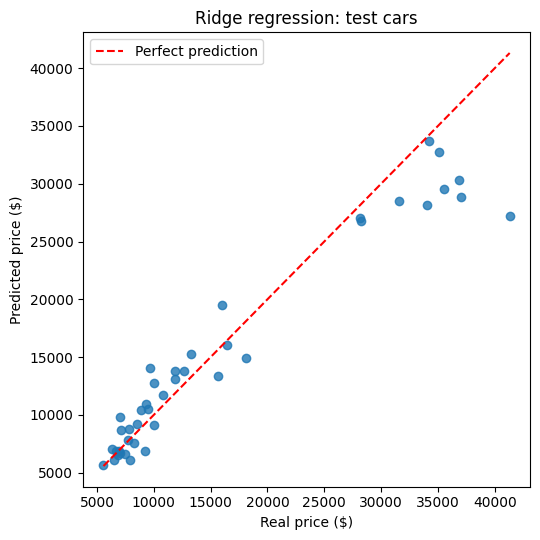

In [13]:
plt.figure(figsize=(5.5, 5.5))                                             # square figure
plt.scatter(y_test, tuned_pred, alpha=0.8)                                 # one dot per test car
low, high = y_test.min(), y_test.max()                                     # lowest and highest real price
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")      # the line where prediction equals reality
plt.xlabel("Real price ($)")                                               # x-axis label
plt.ylabel("Predicted price ($)")                                          # y-axis label
plt.title("Ridge regression: test cars")                                   # title
plt.legend()                                                               # show the legend
plt.tight_layout()                                                         # tidy the layout
plt.savefig("predicted_vs_real.png", dpi=150)                              # save the picture for the README
plt.show()                                                                 # draw the chart

## Step 11: Which features matter most?

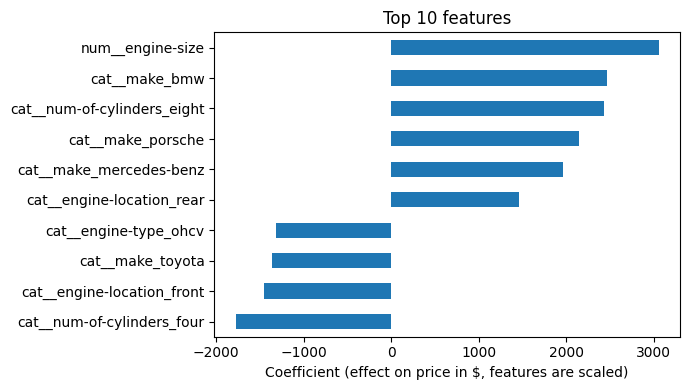

In [14]:
names = tuned_model.named_steps["preprocess"].get_feature_names_out()      # names of all columns after preprocessing
coefs = tuned_model.named_steps["ridge"].coef_.ravel()                     # the learned coefficients
top = pd.Series(coefs, index=names).sort_values(key=abs, ascending=False).head(10)   # 10 largest by absolute size
top = top.sort_values()                                                    # sort for a tidy chart
top.plot(kind="barh", figsize=(7, 4))                                      # horizontal bar chart
plt.xlabel("Coefficient (effect on price in $, features are scaled)")      # x-axis label
plt.title("Top 10 features")                                               # title
plt.tight_layout()                                                         # tidy the layout
plt.show()                                                                 # draw the chart

## Step 12: Save the results

In [15]:
results_table.to_csv("task2_results.csv", index=False)                     # save the results table
from google.colab import files                                             # Colab download tool
files.download("task2_results.csv")                                        # download the CSV
files.download("predicted_vs_real.png")                                    # download the chart

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
1. **Ridge (alpha = 1.0):** on the 41 test cars, R² is 0.9253 and RMSE is $3,023.52. The model explains about 93% of the change in car prices, and a typical mistake is about $3,000.
2. **Ridge versus plain Linear Regression:** plain Linear Regression gets R² 0.9131 and RMSE $3,261.16. So Ridge (alpha = 1.0) is better by about $238 RMSE. Cross-validation on the training cars picked alpha = 3 (CV RMSE $2,536, against $2,546 for alpha = 1, which is almost the same). On the test cars alpha = 3 scored R² 0.9012 and RMSE $3,476.26, a little worse than alpha = 1. I kept alpha = 3 as the final model because I chose it without looking at the test cars. Choosing alpha by the test score would be cheating. The gaps are small and the test set has only 41 cars, so I do not claim that one Ridge setting is clearly better. What I can say is that all three models give a similar result.
3. **Reading the result:** the dots in the chart are close to the red line for cheap cars (under about $15,000). For expensive cars (above about $28,000) the model predicts too low. For example, a car that really costs about $41,000 is predicted at about $27,000. A linear model has trouble with the few very expensive cars. An error of $3,000 is small for a $35,000 car but big for a $7,000 car.
4. **Limits:** only 201 cars, one train/test split, and the prices are from 1985. To improve it next, I could predict the log of the price, or try a non-linear model such as Random Forest.